In [1]:
get_ipython().run_line_magic('matplotlib', 'inline')
import sys, platform, json, importlib.metadata, torch
assert not torch.cuda.is_available(), 'CPU teaching lane unexpectedly sees CUDA'
identity = dict(executable=sys.executable, prefix=sys.prefix, python=platform.python_version(), platform=platform.platform(), cuda_available=torch.cuda.is_available(), torch_cuda_build=torch.version.cuda, packages={name:importlib.metadata.version(name) for name in ['torch','numpy','matplotlib','nbformat','nbclient','ipykernel','transformers','tokenizers','peft']})
print('__DONGXI_KERNEL_IDENTITY__:' + json.dumps(identity, sort_keys=True))

__DONGXI_KERNEL_IDENTITY__:{"cuda_available": false, "executable": "/tmp/dongxi-cs336-g9l7v90r/venv/bin/python", "packages": {"ipykernel": "7.4.0", "matplotlib": "3.10.8", "nbclient": "0.11.0", "nbformat": "5.11.1", "numpy": "2.5.3", "peft": "0.20.0", "tokenizers": "0.23.2", "torch": "2.14.1+cpu", "transformers": "5.18.0"}, "platform": "Linux-6.17.0-1031-nvidia-aarch64-with-glibc2.39", "prefix": "/tmp/dongxi-cs336-g9l7v90r/venv", "python": "3.12.3", "torch_cuda_build": null}


# Make a budget prediction before revealing the next curve

Machine: CPU, authored simulation plus read-only bounded tiny-study receipts. Time: 45–60 minutes. Prerequisites: Chapter6 optimization, Chapter7 calibration versus evaluation. Deliverable: a frozen prediction, held-out error report, and a diagnosis of an unidentifiable fit.

A decreasing loss curve from one model is not a model-size scaling law. We need several sizes under several equal-compute budgets, an objective to fit and a target withheld from recipe selection. Here C≈6ND counts approximate dense training FLOPs, N parameters and D presented tokens. It excludes nonlinear work, hardware efficiency, many attention effects and data preparation. D is not automatically unique data. All smooth curves below are original authored simulations, never observed Stanford or TinyStories runs.

## 1. Find an optimum along equal-compute curves

### Prediction

The authored surface is L=2+20/√N+20/√D with D=C/(6N). Predict the optimal allocation and how optimal N changes when C quadruples.

### Checkpoint

Use only the first three budgets. Plot every sampled size, choose interior grid optima and fit log optimal N and log excess loss. Keep the fourth budget hidden.

### Reference solution

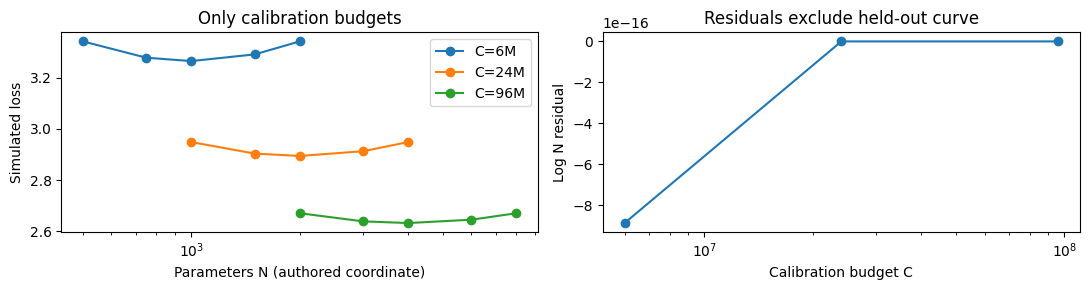

Fit exponents: 0.5000000000000002 -0.25 optima: ({'compute_budget': 6000000.0, 'parameters': 1000, 'loss': 3.264911064067352}, {'compute_budget': 24000000.0, 'parameters': 2000, 'loss': 2.8944271909999153}, {'compute_budget': 96000000.0, 'parameters': 4000, 'loss': 2.632455532033676})


In [2]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/dongxi_llms').is_dir());sys.path.insert(0,str(ROOT/'src'))
from dongxi_llms.scaling_lab import simulated_rows,fit_isoflops,freeze_prediction,evaluate_holdout,bootstrap_predictions,ScalingFitError
calibration=simulated_rows(budgets=(6e6,24e6,96e6))
law=fit_isoflops(calibration)
fig,axes=plt.subplots(1,2,figsize=(11,3))
for budget in law.observed_budgets:
    rows=[r for r in calibration if r['compute_budget']==budget];ns=sorted({r['parameters'] for r in rows});means=[np.mean([r['loss'] for r in rows if r['parameters']==n]) for n in ns]
    axes[0].plot(ns,means,'o-',label=f'C={budget/1e6:g}M')
axes[0].set(xscale='log',xlabel='Parameters N (authored coordinate)',ylabel='Simulated loss',title='Only calibration budgets');axes[0].legend()
axes[1].plot(law.observed_budgets,law.log_parameter_residuals,'o-');axes[1].set(xscale='log',xlabel='Calibration budget C',ylabel='Log N residual',title='Residuals exclude held-out curve');plt.tight_layout();plt.show()
print('Fit exponents:',law.parameter_exponent,law.excess_loss_exponent,'optima:',law.optima)

### Reference explanation

Write x=N and y=D with xy=C/6 fixed. Since x⁻¹/²y⁻¹/² is fixed, their sum is minimized when x=y: N*=D*=√(C/6). Thus optimal N grows as C¹/², while L*−2=40(C/6)⁻¹/⁴. Quadrupling C doubles optimal N. Three calibration budgets bracket their optima at1000,2000,4000; the authored zero-noise fit should recover exponents0.5 and−0.25 within1e-12. Knowing the loss floor2 is part of this simulation; a real LM's asymptotic floor is another estimation problem. Small residuals do not test extrapolation.

![Reference plot: 1. Find an optimum along equal-compute curves. Axis labels identify the mechanism quantities.](../../figures/chapter-06/cs336-03_scaling_prediction-01.png)

Read this preview alongside the explanation above. Regenerate it by running the adjacent reference cell; simulated curves and retained measurements keep their stated evidence labels.


## 2. Freeze the decision before the hidden budget

### Prediction

At C=384M, predict N*,D*,loss and relative size error before revealing any rows. Would you choose the same N under a second unseen budget192M?

### Checkpoint

Create a hashed prediction object using only calibration, then evaluate the entire held-out384M budget. Retain all sizes and seeds, not only the favorable point.

### Reference solution

Frozen prediction: {
  "status": "prediction-frozen-before-holdout",
  "law": {
    "log_parameter_intercept": -0.8958797346140308,
    "parameter_exponent": 0.5000000000000002,
    "log_excess_loss_intercept": 4.13681932142095,
    "excess_loss_exponent": -0.25,
    "assumed_loss_floor": 2.0,
    "calibration_sha256": "9bdc564d7d5562d840d4da50d70956fb1b198deb2d08be6688f7cf4f024b8835",
    "observed_budgets": [
      6000000.0,
      24000000.0,
      96000000.0
    ],
    "optima": [
      {
        "compute_budget": 6000000.0,
        "parameters": 1000,
        "loss": 3.264911064067352
      },
      {
        "compute_budget": 24000000.0,
        "parameters": 2000,
        "loss": 2.8944271909999153
      },
      {
        "compute_budget": 96000000.0,
        "parameters": 4000,
        "loss": 2.632455532033676
      }
    ],
    "log_parameter_residuals": [
      -8.881784197001252e-16,
      0.0,
      0.0
    ],
    "contract": [
      "authored-simulation",
      "surface-

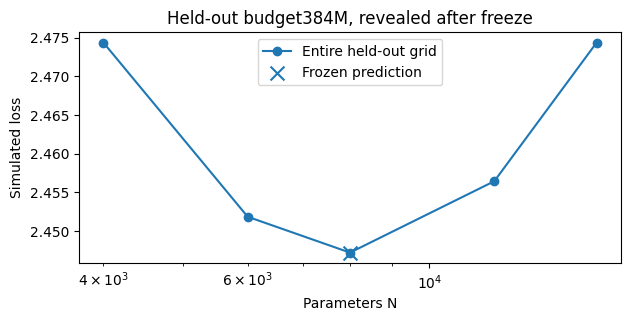

Relative N error: 0.0 optimal loss error: 0.0 rows retained: 15


In [3]:
frozen=freeze_prediction(law,384e6)
print('Frozen prediction:',json.dumps(frozen,indent=2))
print('A second unseen-budget decision:',law.predict(192e6))
# The held-out surface is generated only after the prediction above is frozen.
heldout_rows=simulated_rows(budgets=(384e6,))
heldout=evaluate_holdout(frozen,heldout_rows)
ns=sorted(heldout['mean_loss_by_size']);losses=[heldout['mean_loss_by_size'][n] for n in ns]
fig,ax=plt.subplots(figsize=(7,3));ax.plot(ns,losses,'o-',label='Entire held-out grid');ax.scatter([frozen['prediction']['parameters']],[frozen['prediction']['loss']],marker='x',s=100,label='Frozen prediction');ax.set(xscale='log',xlabel='Parameters N',ylabel='Simulated loss',title='Held-out budget384M, revealed after freeze');ax.legend();plt.show()
print('Relative N error:',heldout['parameter_relative_error'],'optimal loss error:',heldout['optimal_loss_error'],'rows retained:',len(heldout['entire_budget_rows']))

### Reference explanation

The frozen384M prediction is N≈8000,D≈8000,L≈2.447214. The192M decision is N≈5656.854, so optimal allocation changes with the budget. In this known noiseless surface, relative size and optimal-loss errors are numerically near0; the holdout retains15 rows spanning every grid size and replicate. The hash detects changes to the frozen prediction object; temporal discipline still relies on execution order and the saved receipt. On the tiny measured study, target compute is quantized by whole updates and is reported beside the actual6ND coordinate.

![Reference plot: 2. Freeze the decision before the hidden budget. Axis labels identify the mechanism quantities.](../../figures/chapter-06/cs336-03_scaling_prediction-02.png)

Read this preview alongside the explanation above. Regenerate it by running the adjacent reference cell; simulated curves and retained measurements keep their stated evidence labels.


## 3. Noise intervals are conditional on what you sampled

### Prediction

Will resampling these replicate losses capture changed architecture, finite data reuse or a wrong surface formula? Predict what happens if noise pushes a grid minimum to an edge.

### Checkpoint

Bootstrap each size/budget replicate group. Keep failed fits, then compare the result with a fit on only two budgets.

### Reference solution

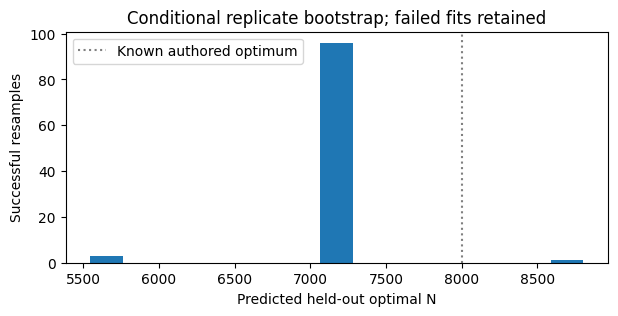

Percentile interval: [6364.646478653733, 7268.482371328557] failed fits: 0
Sparse-grid refusal: At least three distinct calibration budgets required


In [4]:
noisy=simulated_rows(budgets=(6e6,24e6,96e6),noise=.03)
uncertainty=bootstrap_predictions(noisy,384e6,draws=100,seed=6604)
values=[r['parameters'] for r in uncertainty['predictions']]
fig,ax=plt.subplots(figsize=(7,3));ax.hist(values,bins=15);ax.axvline(8000,color='gray',linestyle=':',label='Known authored optimum');ax.set(xlabel='Predicted held-out optimal N',ylabel='Successful resamples',title='Conditional replicate bootstrap; failed fits retained');ax.legend();plt.show()
print('Percentile interval:',uncertainty['parameter_percentile_interval'],'failed fits:',len(uncertainty['failed_fits']))
try:fit_isoflops(simulated_rows(budgets=(6e6,24e6)))
except ScalingFitError as error:print('Sparse-grid refusal:',str(error))

### Reference explanation

The bootstrap resamples noisy observations inside the same declared size/budget grid. Its interval is conditional on that grid and the authored functional form; it excludes hardware efficiency, changed architecture, extrapolation bias and unknown loss floor. An optimum on an edge is not evidence that the true optimum sits there; the grid may be too narrow. Failed fits remain part of the result rather than disappearing from the interval denominator. Two calibration budgets can define a line algebraically but offer inadequate coverage for this lesson's acceptance gate.

The resulting interval may miss the known authored optimum. No coverage guarantee follows from resampling a noisy discrete-grid optimum; inspect this sensitivity rather than adjusting the grid after seeing the target.

![Reference plot: 3. Noise intervals are conditional on what you sampled. Axis labels identify the mechanism quantities.](../../figures/chapter-06/cs336-03_scaling_prediction-03.png)

Read this preview alongside the explanation above. Regenerate it by running the adjacent reference cell; simulated curves and retained measurements keep their stated evidence labels.


## 4. Broken contracts can make a convincing curve

### Prediction

Can a data-reuse run be pooled with the unique-token-coordinate surface? Would excluding large sizes repair a boundary optimum without changing the scientific question?

### Checkpoint

Trigger architecture/data-policy and grid-boundary refusals. Show how repeated presentations differ from unique data, then label the changed surface rather than refitting it as the same experiment.

### Reference solution

architecture changed: Cannot silently pool different mode/architecture/data policies []
data reuse changed: Cannot silently pool different mode/architecture/data policies []
unbracketed optimum: Minimum at grid boundary; optimum not bracketed [{'budget': 6000000.0, 'best': 1000, 'sizes': [500, 750, 1000]}]


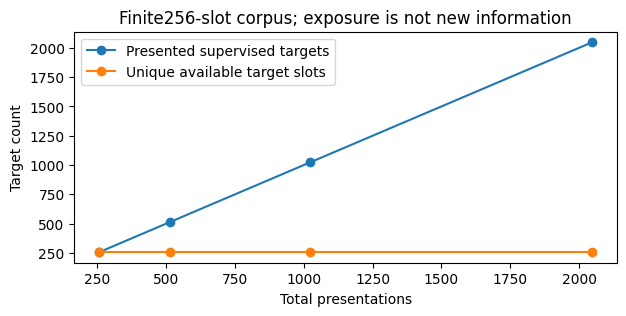

In [5]:
import copy
mixed=copy.deepcopy(calibration);mixed[-1]['architecture']='surface-B'
reused=copy.deepcopy(calibration);reused[-1]['data_policy']='finite-data-repeated'
boundary=[r for r in calibration if r['parameters']<=np.sqrt(r['compute_budget']/6)]
for label,rows in [('architecture changed',mixed),('data reuse changed',reused),('unbracketed optimum',boundary)]:
    try:fit_isoflops(rows)
    except ScalingFitError as error:print(label+':',str(error),error.diagnostics)
presentations=np.array([256,512,1024,2048]);unique=np.minimum(presentations,256)
fig,ax=plt.subplots(figsize=(7,3));ax.plot(presentations,presentations,'o-',label='Presented supervised targets');ax.plot(presentations,unique,'o-',label='Unique available target slots');ax.set(xlabel='Total presentations',ylabel='Target count',title='Finite256-slot corpus; exposure is not new information');ax.legend();plt.show()

### Reference explanation

Contract labels deliberately refuse silent pooling; identical6ND coordinates need not imply comparable losses after architecture or data policy changes. They cannot detect an incorrectly labeled experiment, so the data card and source review remain essential. At2048 presentations from256 target slots, mean exposure is8× while available unique slots stay256. A narrower size range can move the observed minimum to its boundary; dropping inconvenient points does not establish an optimum. New hypotheses need a new predeclared study, rather than hidden retuning of the heldout target.

![Reference plot: 4. Broken contracts can make a convincing curve. Axis labels identify the mechanism quantities.](../../figures/chapter-06/cs336-03_scaling_prediction-04.png)

Read this preview alongside the explanation above. Regenerate it by running the adjacent reference cell; simulated curves and retained measurements keep their stated evidence labels.


## 5. An actual tiny grid may refuse the attractive story

### Prediction

Before reading the bounded CPU receipt, predict whether three widths on a repeated256-target-slot fixture necessarily bracket a compute-optimal size. What would a refusal mean?

### Checkpoint

Read the separately smoke-profiled24-run CPU study. Plot train/dev/test and target versus actual compute coordinates. Do not merge these measured points with the simulated curve.

### Reference solution

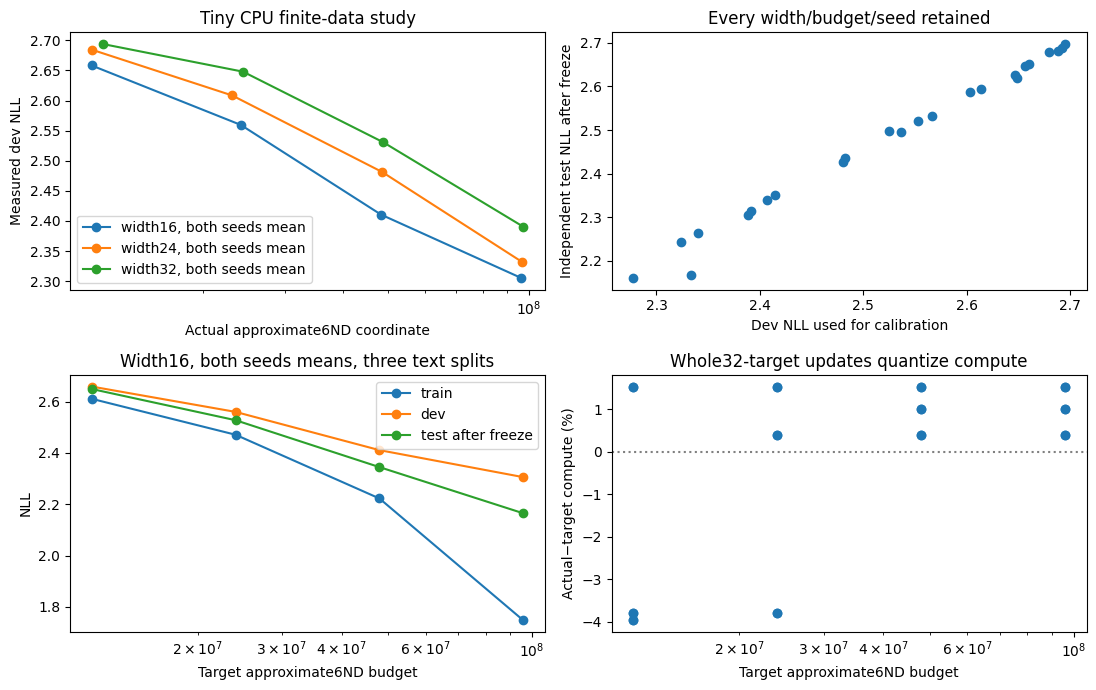

Frozen result: {'status': 'fit-refused-before-holdout', 'error': 'Minimum at grid boundary; optimum not bracketed', 'diagnostics': [{'budget': 12000000, 'best': 5456, 'sizes': [5456, 12024, 21152]}], 'target_budget': 96000000, 'calibration_sha256': '92dd4e4d764e2badbe78bc3874a77ff810e19295c99137a83b1990888e9e4470'}
Failures: [{'stage': 'calibration-fit', 'error': 'Minimum at grid boundary; optimum not bracketed', 'diagnostics': [{'budget': 12000000, 'best': 5456, 'sizes': [5456, 12024, 21152]}]}]
Total targets: 18880 seconds: 1.3676029000198469


In [6]:
receipt_path=ROOT/'experiments/reports/2026-10-11-cs336-upgrade/run-01/systems/tiny-scaling-matrix.json'
if receipt_path.exists():
    study=json.loads(receipt_path.read_text())['result'];runs=study['all_runs']
    fig,axes=plt.subplots(2,2,figsize=(11,7))
    budgets=sorted({r['compute_budget'] for r in runs})
    for width in sorted({r['width'] for r in runs}):
        selected=[[r for r in runs if r['width']==width and r['compute_budget']==budget] for budget in budgets]
        axes[0,0].plot([np.mean([r['actual_6ND_coordinate'] for r in group]) for group in selected],[np.mean([r['loss'] for r in group]) for group in selected],'o-',label=f'width{width}, both seeds mean')
    axes[0,0].set(xscale='log',xlabel='Actual approximate6ND coordinate',ylabel='Measured dev NLL',title='Tiny CPU finite-data study');axes[0,0].legend()
    axes[0,1].scatter([r['loss'] for r in runs],[r['test_loss_after_freeze'] for r in runs]);axes[0,1].set(xlabel='Dev NLL used for calibration',ylabel='Independent test NLL after freeze',title='Every width/budget/seed retained')
    for key,label in [('train_loss','train'),('loss','dev'),('test_loss_after_freeze','test after freeze')]:
        values=[np.mean([r[key] for r in runs if r['width']==16 and r['compute_budget']==budget]) for budget in budgets]
        axes[1,0].plot(budgets,values,'o-',label=label)
    axes[1,0].set(xscale='log',xlabel='Target approximate6ND budget',ylabel='NLL',title='Width16, both seeds means, three text splits');axes[1,0].legend()
    axes[1,1].scatter([r['compute_budget'] for r in runs],[100*(r['actual_6ND_coordinate']/r['compute_budget']-1) for r in runs]);axes[1,1].axhline(0,color='gray',linestyle=':');axes[1,1].set(xscale='log',xlabel='Target approximate6ND budget',ylabel='Actual−target compute (%)',title='Whole32-target updates quantize compute')
    plt.tight_layout();plt.show()
    print('Frozen result:',study['frozen_prediction']);print('Failures:',study['failures']);print('Total targets:',study['total_presented_targets'],'seconds:',study['aggregate_runtime_seconds'])
else:
    print('Empirical receipt unavailable; this cell makes no measured result claim. Run the separately predeclared bounded protocol first.')

### Reference explanation

A grid can show learning without identifying an interior optimum. If the best dev size lies on a boundary at any calibration budget, the study freezes that refusal before training the held-out budget and reports no optimal-size prediction. All24 runs and the independent test are still informative local evidence. The actual approximate compute coordinate differs slightly from its target because a whole update presents32 targets. The shared finite transition fixture, size-dependent aspect ratios and budget-specific cosine horizon limit causal interpretation. No local result predicts real story quality, a large-model loss or Spark wall time.

![Reference plot: 5. An actual tiny grid may refuse the attractive story. Axis labels identify the mechanism quantities.](../../figures/chapter-06/cs336-03_scaling_prediction-05.png)

Read this preview alongside the explanation above. Regenerate it by running the adjacent reference cell; simulated curves and retained measurements keep their stated evidence labels.


## Evidence and next step

Submit the calibration identity, prediction hash, full target grid and error/refusal. Distinguish the held-out compute budget from the independent text test. The [focused solutions](SYSTEMS_SOLUTIONS.md) map these checks to AssignmentD. A recommendation must specify which uncertainty could reverse the chosen allocation; simulated recovery alone is a correctness check, not empirical evidence for the same exponent in language models.